# CS110 · Plotly and Seaborn: Going Beyond Matplotlib
### A Google Colab tutorial using Death Valley weather data



In our previous Colab worksheet, we used **Matplotlib** to draw temperature graphs. In this notebook, we will use the **same weather files** to learn two other Python plotting libraries: **Plotly** and **Seaborn**.

**Learning goals**
- Make familiar line graphs using three different plotting libraries.
- Explore how **Plotly** makes graphs interactive (hover, zoom, and hide a series).
- Explore how **Seaborn** makes it easier to visualize patterns and distributions.
- Decide which library is a good match for a particular question in your final project.

**How to use this notebook:** Run cells from top to bottom. Read the short explanations, study the resulting figures, and try the small exploration tasks. There are **no quizzes or automatic checks**.

---
## 1. Three libraries, three useful approaches

| Library | Typical import | Main strength | What you get |
|---|---|---|---|
| **Matplotlib** | `import matplotlib.pyplot as plt` | Fine control over the appearance of a figure | Usually a static image |
| **Plotly** | `import plotly.express as px` | Interactive figures with little extra code | Hover values, zoom, pan, and a clickable legend |
| **Seaborn** | `import seaborn as sns` | Quick statistical plots and comparisons between groups | Clear static plots built on Matplotlib |

There is no single *best* library. They often show the **same information** in different ways.

> **Connection to what you know:** Seaborn draws its charts using Matplotlib, so we can still use `plt.title()`, `plt.xlabel()`, and `plt.show()` after a Seaborn call. Plotly uses a different figure object, which we customize with methods such as `fig.update_layout()`.

---
## 2. Download the same weather files

Run the following cell **once**. It downloads these three CSV files directly into the Google Colab working folder:

- `death_valley_2021_simple.csv` — short sample from 2021
- `death_valley_2021_full.csv` — the full 2021 dataset
- `death_valley_2018_full.csv` — 2018 data for comparisons


In [17]:
from urllib.request import urlretrieve

course_url = "https://raw.githubusercontent.com/lopezbec/intro_python_notebooks/main/"
public_copies = {
    "death_valley_2021_simple.csv": "https://raw.githubusercontent.com/ehmatthes/pcc_3e/main/chapter_16/the_csv_file_format/weather_data/death_valley_2021_simple.csv",
    "death_valley_2021_full.csv": "https://raw.githubusercontent.com/ehmatthes/pcc_3e/main/chapter_16/the_csv_file_format/weather_data/death_valley_2021_full.csv",
    "death_valley_2018_full.csv": "https://raw.githubusercontent.com/mavjav-edu/pcc-chapter-16/master/death_valley_2018_full.csv",
}

for filename, public_url in public_copies.items():
    try:
        urlretrieve(course_url + filename, filename)
        print("Downloaded from course repo:", filename)
    except Exception:
        urlretrieve(public_url, filename)
        print("Downloaded from public copy:", filename)

Downloaded from course repo: death_valley_2021_simple.csv
Downloaded from course repo: death_valley_2021_full.csv
Downloaded from course repo: death_valley_2018_full.csv


---
## 3. Load the CSV files into Pandas

In the Matplotlib lecture, we used `csv.DictReader()` and created separate lists. Here, **Pandas** lets us keep the columns together in a **DataFrame** (a table). Plotly and Seaborn can both read columns directly from that table.

A few important details:
- `DATE` needs to be interpreted as a date, not just a string.
- `TMAX` and `TMIN` are temperatures measured in **degrees Fahrenheit (°F)**.
- Some readings may be missing. We use `errors="coerce"` to represent those entries as missing values rather than incorrectly treating them as zero.

The function below lets us repeat the same reading and preparation steps for all three files.

In [33]:
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import seaborn as sns


def load_weather(filename):
    # Read the CSV file as a table.
    weather = pd.read_csv(filename)

    # Convert dates and temperatures into the appropriate data types.
    weather["DATE"] = pd.to_datetime(weather["DATE"])
    weather["TMAX"] = pd.to_numeric(weather["TMAX"], errors="coerce")
    weather["TMIN"] = pd.to_numeric(weather["TMIN"], errors="coerce")
    return weather.sort_values("DATE")


weather_simple = load_weather("death_valley_2021_simple.csv")
weather_2021 = load_weather("death_valley_2021_full.csv")
weather_2018 = load_weather("death_valley_2018_full.csv")

# Preview just the columns we plan to visualize.
weather_simple[["DATE", "TMAX", "TMIN"]].head()

,DATE,TMAX,TMIN
0,2021-01-01,71,51
1,2021-01-02,67,42
2,2021-01-03,66,41
3,2021-01-04,66,41
4,2021-01-05,70,40


### Reading the same data in two ways

In our previous worksheet, we built lists with `csv.DictReader()`:

```python
# From our earlier Matplotlib approach:
dates = []
highs = []
# Inside a loop, we appended each date and TMAX value.
```

With Pandas, columns can be used directly:

```python
weather_simple["DATE"]  # Dates in the table
weather_simple["TMAX"]  # Daily high temperatures
```

**The important idea is unchanged:** Choose an x-variable, choose a y-variable, then select the kind of graph that helps answer your question.

---
## 4. Our starting point: a Matplotlib line graph

**Question:** How did the daily **maximum (TMAX)** and **minimum (TMIN)** temperatures change during the sample period?

This first example should look familiar. We specify the x and y columns explicitly, create two lines, then add labels and a legend.

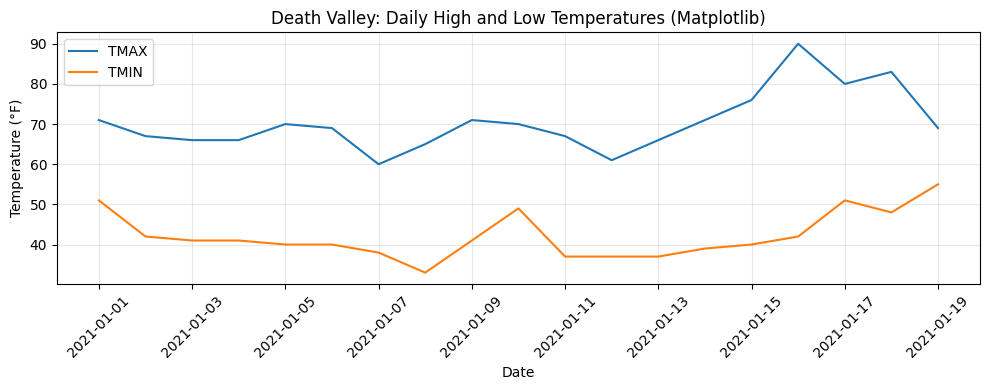

In [19]:
# Matplotlib: two temperature lines.
plt.figure(figsize=(10, 4))
plt.plot(weather_simple["DATE"], weather_simple["TMAX"], label="TMAX")
plt.plot(weather_simple["DATE"], weather_simple["TMIN"], label="TMIN")
plt.title("Death Valley: Daily High and Low Temperatures (Matplotlib)")
plt.xlabel("Date")
plt.ylabel("Temperature (°F)")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

---
## 5. Plotly: the same graph, now interactive

**Plotly Express** (`px`) creates many common charts with one main function call. Compare the line that makes the plot:

| Matplotlib | Plotly Express |
|---|---|
| `plt.plot(x_values, y_values)` | `px.line(data, x="column", y="column")` |
| `plt.title("...")` | `title="..."` inside `px.line()` |
| `plt.xlabel("...")` | `labels={"column": "..."}` |
| `plt.show()` | `fig.show()` |

For **two lines**, Plotly accepts a list of the temperature columns in `y=["TMAX", "TMIN"]`.

In [34]:
# Plotly: exactly the same two temperature series.
fig = px.line(
    weather_simple,
    x="DATE",
    y=["TMAX", "TMIN"],
    title="Death Valley: Daily High and Low Temperatures (Plotly)",
    labels={"DATE": "Date", "value": "Temperature (°F)", "variable": "Measurement"},
)
fig.show()

### Explore the interactive graph

Move your cursor over the lines. Then try:

1. **Hover:** See the date and exact temperature for a point.
2. **Zoom:** Click and drag over a smaller date range.
3. **Reset:** Double-click in the plot area or use the toolbar's reset/auto-scale option.
4. **Legend:** Click `TMAX` or `TMIN` to temporarily hide/show one line.

**Why it matters:** Interactive figures are especially useful when exploring large datasets or sharing a result with someone who wants to inspect individual observations.

**Notice:** We did not write any code for the hover labels or zoom controls. Plotly supplies those automatically.

### A second Plotly example: explore the entire year

The full-year CSV contains many more dates. Plotly can add a **range slider** below the x-axis, making it easy to focus on one month or season. This is especially useful for the final project when a graph contains many observations.

In [35]:
fig = px.line(
    weather_2021,
    x="DATE",
    y=["TMAX", "TMIN"],
    title="Death Valley: Temperatures Across 2021",
    labels={"DATE": "Date", "value": "Temperature (°F)", "variable": "Measurement"},
)
fig.update_layout(hovermode="x unified", height=460)
fig.update_xaxes(rangeslider_visible=True)
fig.show()

---
## 6. Seaborn: start with a line graph

Seaborn also uses short plotting commands, and it works particularly well with **DataFrames**.

A convenient feature is **`hue`**, which assigns different colors to different categories. For the two temperature series, we first arrange our table into a form with a single temperature column and a column that says which measurement it is.

| DATE | Measurement | Temperature (°F) |
|---|---|---|
| a date | TMAX | daily high |
| the same date | TMIN | daily low |

This is called **long-format data**. The `melt()` method transforms our two temperature columns into this format; the weather measurements themselves do not change.

In [36]:
# Reshape the table so Seaborn can color the lines by measurement.
weather_long = weather_simple.melt(
    id_vars="DATE",
    value_vars=["TMAX", "TMIN"],
    var_name="Measurement",
    value_name="Temperature (°F)",
)

weather_long.head()

,DATE,Measurement,Temperature (°F)
0,2021-01-01,TMAX,71
1,2021-01-02,TMAX,67
2,2021-01-03,TMAX,66
3,2021-01-04,TMAX,66
4,2021-01-05,TMAX,70


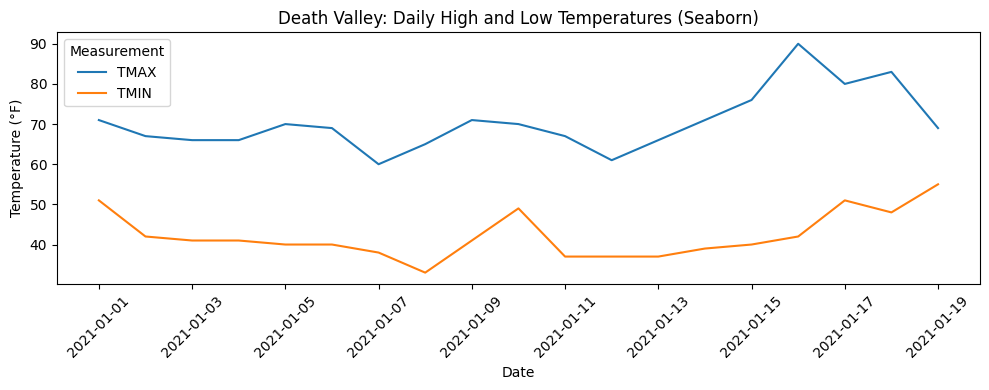

In [37]:
# Seaborn: a line graph using columns and a category (hue).
plt.figure(figsize=(10, 4))
sns.lineplot(
    data=weather_long,
    x="DATE",
    y="Temperature (°F)",
    hue="Measurement",
    estimator=None,
)
plt.title("Death Valley: Daily High and Low Temperatures (Seaborn)")
plt.xlabel("Date")
plt.ylabel("Temperature (°F)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### One question, three plotting approaches

You just created **the same type of chart** using three libraries:

| Step | Matplotlib | Plotly Express | Seaborn |
|---|---|---|---|
| Draw a line | `plt.plot(...)` | `px.line(...)` | `sns.lineplot(...)` |
| Use a table directly | You select each column | `data=weather` | `data=weather` |
| Separate groups | Draw separate lines | `y=[...]` or `color=...` | `hue=...` |
| Title and axes | `plt.title()`, `plt.xlabel()` | `title=...`, `labels=...` | Often use Matplotlib functions afterward |
| Interaction | Usually static | Hover/zoom are built in | Usually static |

**Observation:** Seaborn is not a replacement for Matplotlib. It adds a convenient, data-oriented interface *on top of* Matplotlib. Plotly takes a different approach by returning an interactive figure.

---
## 7. An important new question: How are temperatures distributed?

A **line graph** is useful when the order of dates matters. A **histogram** answers a different question: *How many days had highs in each temperature range?*

To compare the code fairly, we will first draw a histogram of the **2021 daily maximum temperatures** with Matplotlib and then draw the same kind of graph with Seaborn.

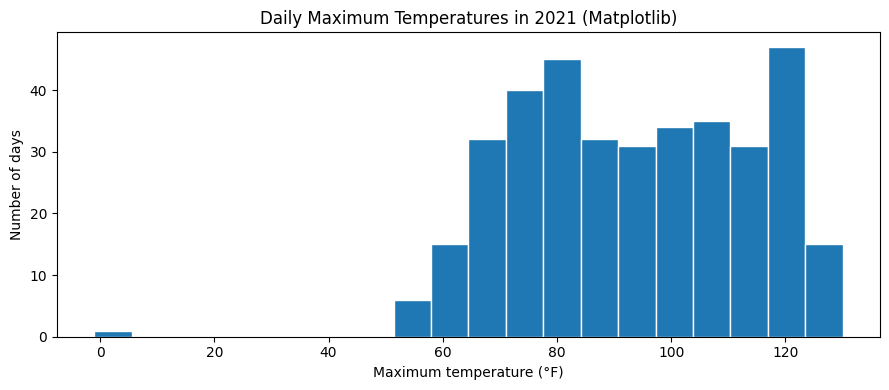

In [38]:
# Matplotlib histogram: count the days in each temperature range.
plt.figure(figsize=(9, 4))
plt.hist(weather_2021["TMAX"].dropna(), bins=20, edgecolor="white")
plt.title("Daily Maximum Temperatures in 2021 (Matplotlib)")
plt.xlabel("Maximum temperature (°F)")
plt.ylabel("Number of days")
plt.tight_layout()
plt.show()

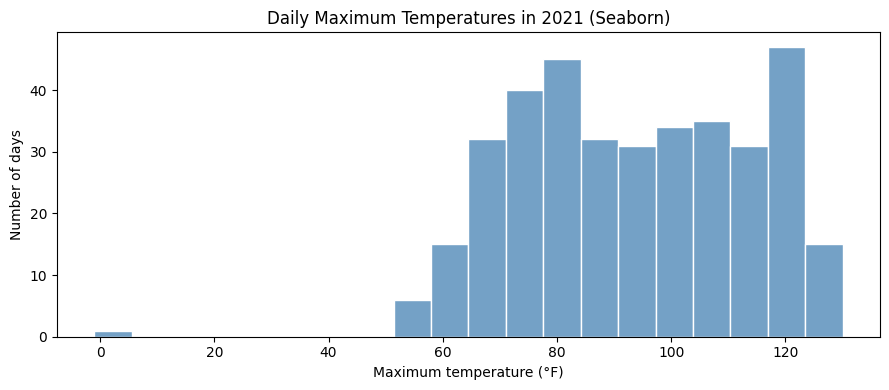

In [39]:
# Seaborn histogram: same question, DataFrame-based syntax.
plt.figure(figsize=(9, 4))
sns.histplot(data=weather_2021, x="TMAX", bins=20, color="steelblue", edgecolor="white")
plt.title("Daily Maximum Temperatures in 2021 (Seaborn)")
plt.xlabel("Maximum temperature (°F)")
plt.ylabel("Number of days")
plt.tight_layout()
plt.show()

### Why use Seaborn for a histogram?

Both libraries can produce excellent histograms. Seaborn is convenient when you want to work directly with a table and later compare **groups** using `hue`, or switch to another statistical plot such as a **box plot** or **scatter plot**.

**Think about it:** What information does the histogram reveal that the time-series line chart makes difficult to see?

---
## 8. Seaborn: compare the months with a box plot

A **box plot** summarizes the distribution of a numerical variable for each group. Instead of drawing 365 individual high temperatures, this chart summarizes temperatures **month by month**.

- The middle line in each box shows the **median** (middle value).
- The box spans the middle 50% of observed values.
- The whiskers and separate points help show spread and potentially unusual observations.

This type of plot is useful in the final project when you want to compare distributions across categories.

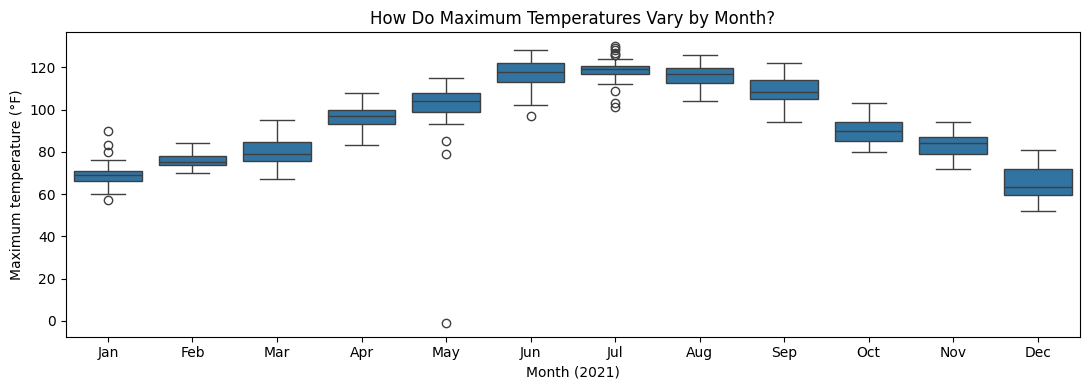

In [40]:
# Add a month label that Seaborn can use as a category.
weather_2021["Month"] = weather_2021["DATE"].dt.strftime("%b")
month_order = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
               "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

plt.figure(figsize=(11, 4))
sns.boxplot(data=weather_2021, x="Month", y="TMAX", order=month_order)
plt.title("How Do Maximum Temperatures Vary by Month?")
plt.xlabel("Month (2021)")
plt.ylabel("Maximum temperature (°F)")
plt.tight_layout()
plt.show()

---
## 9. Plotly: look for a relationship with a scatter plot

A **scatter plot** helps us explore the relationship between **two numerical variables**. In this example, each dot represents a day, with the daily **minimum temperature** on the x-axis and the daily **maximum temperature** on the y-axis.

Plotly uses `px.scatter(...)`. We will also use the `color=` parameter to show which **season** each observation belongs to. Hover over the points to inspect exact dates.

In [41]:
# Create a season category from the month number.
season_by_month = {
    12: "Winter", 1: "Winter", 2: "Winter",
    3: "Spring", 4: "Spring", 5: "Spring",
    6: "Summer", 7: "Summer", 8: "Summer",
    9: "Fall", 10: "Fall", 11: "Fall",
}
weather_2021["Season"] = weather_2021["DATE"].dt.month.map(season_by_month)

fig = px.scatter(
    weather_2021,
    x="TMIN", y="TMAX", color="Season",
    hover_data=["DATE"],
    title="Daily Lows vs. Highs in Death Valley (2021)",
    labels={"TMIN": "Minimum temperature (°F)",
            "TMAX": "Maximum temperature (°F)"},
)
fig.show()

### Try the same scatter plot with Seaborn

We can reuse the **exact same prepared table**. Notice that `hue="Season"` in Seaborn plays a similar role to `color="Season"` in Plotly.

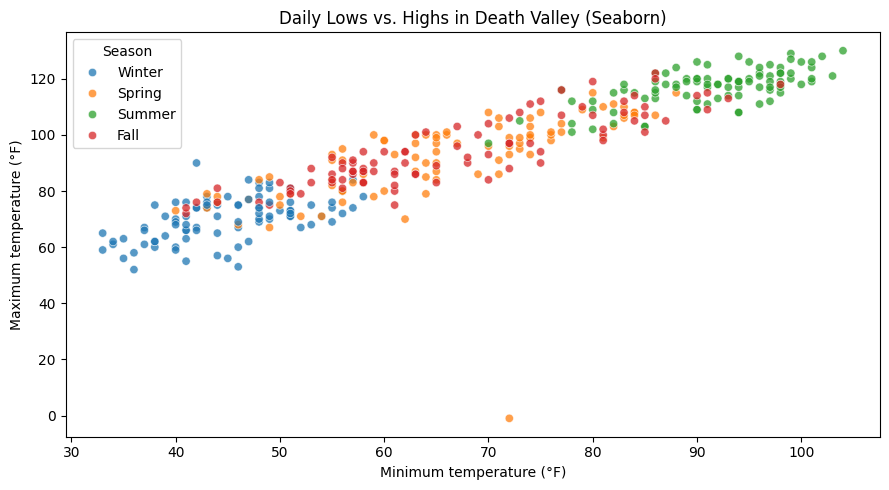

In [42]:
plt.figure(figsize=(9, 5))
sns.scatterplot(data=weather_2021, x="TMIN", y="TMAX", hue="Season", alpha=0.75)
plt.title("Daily Lows vs. Highs in Death Valley (Seaborn)")
plt.xlabel("Minimum temperature (°F)")
plt.ylabel("Maximum temperature (°F)")
plt.tight_layout()
plt.show()

---
## 10. Compare 2018 and 2021

Our earlier worksheet asked us to compare **maximum temperatures in 2018 and 2021**. Let's reuse that question and see how the libraries help.

We will put both years on the same **day-of-year axis**: day 1 is January 1, and day 365 is December 31. This makes the seasonal patterns directly comparable. Both 2018 and 2021 are non-leap years.

In [43]:
# Prepare a combined table for the two years.
compare_2018 = weather_2018[["DATE", "TMAX"]].copy()
compare_2018["Year"] = "2018"

compare_2021 = weather_2021[["DATE", "TMAX"]].copy()
compare_2021["Year"] = "2021"

comparison = pd.concat([compare_2018, compare_2021], ignore_index=True)
comparison["Day of Year"] = comparison["DATE"].dt.dayofyear
comparison = comparison.dropna(subset=["TMAX"])

comparison[["Day of Year", "TMAX", "Year"]].head()

,Day of Year,TMAX,Year
0,1,65,2018
1,2,61,2018
2,3,69,2018
3,4,69,2018
4,5,74,2018


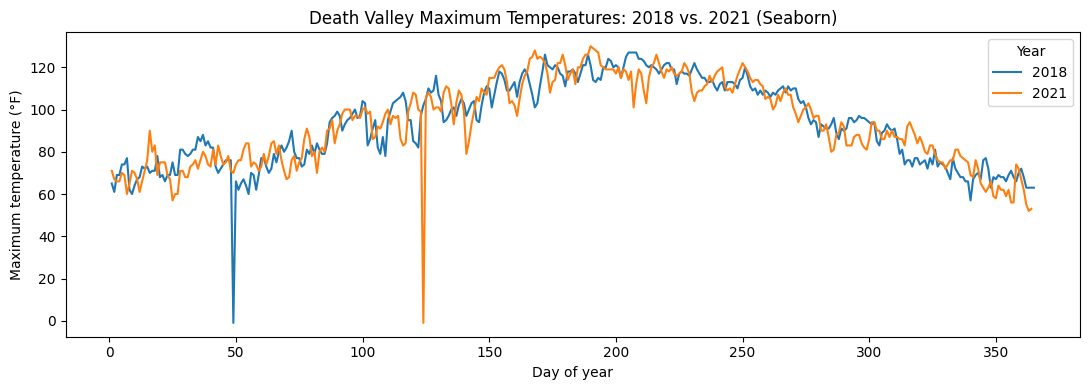

In [44]:
# Seaborn: comparison using a category in hue.
plt.figure(figsize=(11, 4))
sns.lineplot(data=comparison, x="Day of Year", y="TMAX", hue="Year", estimator=None)
plt.title("Death Valley Maximum Temperatures: 2018 vs. 2021 (Seaborn)")
plt.xlabel("Day of year")
plt.ylabel("Maximum temperature (°F)")
plt.tight_layout()
plt.show()

In [45]:
# Plotly: same comparison with hover and zoom.
fig = px.line(
    comparison,
    x="Day of Year", y="TMAX", color="Year",
    title="Death Valley Maximum Temperatures: 2018 vs. 2021 (Plotly)",
    labels={"TMAX": "Maximum temperature (°F)"},
)
fig.show()

---
## 11. Your turn: experiment with a graph

Choose **one** of these explorations. Use the code cell below to make your own plot.

**Option A — Plotly:** Modify the 2021 line graph to focus on a smaller time period. Try a different title or explore the `color` and `markers` options.

**Option B — Seaborn:** Create a histogram of **TMIN** instead of TMAX. What does it reveal about the minimum temperatures?

**Option C — Comparing years:** Try a different way to compare 2018 and 2021, such as two separate histograms or a Seaborn box plot grouped by `Year`.

Your graph should have a descriptive title and labels that include temperature units. There is no single required visual style.

In [32]:
# Your exploration: write or adapt a plotting example here.
# Hint: weather_2021, weather_2018, and comparison are ready to use.

### Describe what you learned

In the text below, write **2–3 sentences** describing a pattern, comparison, or unexpected feature that you observed in your plot. Explain why you chose that chart type.

**What my graph shows:**

*Write your observation here.*

**Why this graph is a useful choice:**

*Write your explanation here.*

---
## 12. Which library should you use for your final project?

| If your goal is to… | Consider… | Why? |
|---|---|---|
| Customize each aspect of a static chart | **Matplotlib** | Offers detailed control of labels, axes, marks, and layout |
| Let viewers hover over individual data points | **Plotly** | Interactivity comes built in |
| Explore distributions or compare groups quickly | **Seaborn** | Convenient functions for histograms, box plots, and group-based coloring |
| Build a time-series line chart | **Any of the three** | All three are suitable; choose based on presentation needs |

In your **CS110 Final Project: Visualizing Data with Python**, your visualizations should help answer a research question, highlight meaningful patterns, and include well-labeled axes with relevant units. You can mix libraries if it helps tell your data story.

**Useful documentation**
- [Matplotlib tutorials](https://matplotlib.org/stable/tutorials/index.html)
- [Plotly Express documentation](https://plotly.com/python/plotly-express/)
- [Seaborn introduction](https://seaborn.pydata.org/tutorial/introduction.html)

**Before you finish:** Consider which library you would prefer for an interactive presentation, and which you would prefer for comparing statistical patterns. You may find that the answer is different for each question.